In [1]:
%load_ext autoreload
%autoreload

In [2]:
import os
import sys
import json
from glob import glob
import pickle
from typing import Collection

import pandas as pd
import numpy as np
from tqdm import tqdm

sys.path.append('/home/link/Project/KoBertSum')
sys.path.append('/home/link/Project/KoBertSum/src')
tqdm.pandas()

# 데이터 로드

In [3]:
DATA_PATH = "/home/link/Project/KoBertSum/datasets/hunmin_ko"
train_orig_df = pd.read_csv(f"{DATA_PATH}/orig/train_data.csv")
test_orig_df = pd.read_csv(f"{DATA_PATH}/orig/test_data.csv")
sample_submission_df = pd.read_csv(f"{DATA_PATH}/orig/sample_submission.csv")

In [4]:
train_orig_df

,id,text,summary
0,0,원고가 소속회사의 노동조합에서 분규가 발생하자 노조활동을 구실로 정상적인 근무를 해...,원고가 주동하여 회사업무능률을 저해하고 회사업무상의 지휘명령에 위반하였다면 이에 ...
1,1,수출입업체인 원고가 의류제품을 제조ㆍ수출함에 있어 같은 그룹내 종합무역상사인 소외 ...,수출입업체인 원고가 의류제품을 제조ㆍ수출함에 있어 소외 회사의 직수출실적을 지원하기...
2,2,가등기담보권자가 제소전 화해조항에 따라 자기 명의로 소유권이전의 본등기를 경료한 후...,가등기담보권자가 제소전 화해조항에 의해 자기 명의로 소유권이전의 본등기를 경료하고 ...
3,3,가. 부가가치세법 제22조 제3항 단서에 제1호와 제2호가 동시에 해당한다는 뜻은 ...,부가가치세법 제22조 제3항 단서에 제1호와 제2호가 동시에 해당한다는 의미는 제1...
4,4,소득세법 제116조 제1항의 규정에 의하면 정부는 과세표준확정신고를 하여야 할 자에...,소득세법 제116조 제1항에 따르면 정부는 과세표준확정신고를 해야 할 자에 대해 당...
...,...,...,...
271660,271660,KCGI는 지분 늘려 13.47%로 국민연금과 합치면 20% 넘어 '백기사' 확보 ...,8일 IB업계 관계자는 상속세 납부 과정에서 조 회장 일가의 한진칼 지배구조 약화 ...
271661,271661,"[ 노유정 기자 ] 조양호 한진그룹 회장의 갑작스런 타계 소식이 전해진 8일 오전,...",8일 미국에서 들려온 조양호 한진그룹 회장의 사망 소식에 서울 공항동 대한항공 본사...
271662,271662,[ 김익환 기자 ] 조양호 한진그룹 회장이 타계하면서 그의 재산을 물려받을 장남 조...,"고 조 회장의 한진칼, 한진 등 상장회사의 주식가격 총합은 약 3560억 정도 되며..."
271663,271663,[ 김보형 기자 ] 조양호 한진그룹 회장이 8일 타계하면서 그의 장남인 조원태 대한...,"지난 8일 조양호 한진그룹 회장이 별세하면서 한진그룹은 비상경영체제에 돌입했고, 그..."


In [7]:
test_orig_df.head()

,id,text,summary
0,1,[경주=환경일보] 강광태 기자 = 경주시는 창의적 아이디어를 적극 수렴함으로써 소통...,생성요약문
1,2,"황영민 시장·군수·구청장 직접 제출… 경기도, 복지부·국회에 개선 요구 경기도가 장...",생성요약문
2,3,김대연 기자l saint-jj@hanmail.net 전북도의회는 올해 의회운영의 전...,생성요약문
3,4,대법원 2부(주심 안철상)는 스타 강사 우모씨를 상대로 인터넷 강의 업체 이투스교육...,생성요약문
4,5,"사설 보호무역 확산, G20회의 철저한 준비를 1월 수출이 월별 수출입 동향을 집계...",생성요약문


In [8]:
test_orig_df.shape

(10000, 3)

In [9]:
sample_submission_df.head()

,id,summary
0,1,생성요약문
1,2,생성요약문
2,3,생성요약문
3,4,생성요약문
4,5,생성요약문


In [10]:
sample_submission_df.shape

(10000, 2)

## 데이터 나누기

In [ ]:
    if subdata_group in ["train", "valid"]:
        # df['extractive_sents'] = df.apply(lambda row: list(np.array(row['article_original'])[row['extractive']]) , axis=1)
        df = df[[src_name, tgt_name]]

        if int(train_split_frac) != 1:  # train -> train / dev
            # random split
            train_df = df.sample(frac=train_split_frac, random_state=42)  # random state is a seed value
            valid_df = df.drop(train_df.index)
            if len(train_df) > 0:
                train_df.reset_index(inplace=True, drop=True)
                save_df(train_df, to_dir)
            if len(valid_df) > 0:
                valid_df.reset_index(inplace=True, drop=True)
                save_df(valid_df, to_dir)

# 데이터 전처리

In [7]:
train_df = train_orig_df.copy()
test_df = test_orig_df.copy()

### 클리닝1

In [8]:
#결측치 제거
nan_list = [27556, 34092, 34201, 66897, 133273, 216203]
train_df = train_df[~train_df["id"].isin(nan_list)].reset_index(drop = True)

In [9]:
train_df[train_df["summary"].isna()]
# train_data[train_data['text'].apply(lambda x : type(x) is not str)]

,id,text,summary


In [17]:
save_obj(train_df, f"{DATA_PATH}/df_tmp/train_df.pickle")
save_obj(test_df, f"{DATA_PATH}/df_tmp/test_df.pickle")

### 클리닝2

In [53]:
train_df = load_obj(f"{DATA_PATH}/df_tmp/train_df.pickle")
test_df = load_obj(f"{DATA_PATH}/df_tmp/test_df.pickle")

train_cleand = train_df.copy()
test_cleand = test_df.copy()
train_df[train_df['id']==271567]['text'].values

array(['[ 김보라 기자 ] 본죽을 운영하는 본아이에프 연간 매출이 2000억원을 돌파했다. 최저임금 인상, 가정간편식(HMR) 공세, 각종 식재료 가격 상승 프랜차이즈업계를 덮친 악재 속에 거둔 성과다. 2002년 9월 대학로에서 5000만원짜리 가게로 시작한 죽집은 "아픈 사람이 먹는 죽이 돈이 되겠냐"는 고정관념을 깨고 종합식품기업으로 성장하고 있다.'],
      dtype=object)

In [54]:
from prepro.preprocessor_kr import noise_remove

train_cleand['text'] = train_cleand['text'].progress_apply(noise_remove)
test_cleand['text'] = test_cleand['text'].progress_apply(noise_remove)

train_cleand[train_cleand['id']==271567]['text'].values

100%|██████████| 10000/10000 [00:08<00:00, 1174.67it/s]


array(['본죽을 운영하는 본아이에프 연간 매출이 2000억원을 돌파했다. 최저임금 인상, 가정간편식 공세, 각종 식재료 가격 상승 프랜차이즈업계를 덮친 악재 속에 거둔 성과다. 2002년 9월 대학로에서 5000만원짜리 가게로 시작한 죽집은 "아픈 사람이 먹는 죽이 돈이 되겠냐"는 고정관념을 깨고 종합식품기업으로 성장하고 있다.'],
      dtype=object)

In [55]:
print(train_cleand['text'][271567])

] 액정표시장치 업황 부진에 유가증권시장에서 추락을 거듭하던 LG디스플레이가 최근 회복세를 보여 눈길을 끌고 있다. LCD 패널 가격 하락세가 잦아든 데다 미래 먹거리인 유기발광다이오드 사업의 성장성이 부각된 점이 투자심리 개선으로 이어졌다는 분석이다.


In [56]:
len(train_cleand)

271659

In [57]:
train_cleand = train_cleand[train_cleand["text"].str.len() > 40]
train_cleand

,id,text,summary
0,0,원고가 소속회사의 노동조합에서 분규가 발생하자 노조활동을 구실로 정상적인 근무를 해...,원고가 주동하여 회사업무능률을 저해하고 회사업무상의 지휘명령에 위반하였다면 이에 ...
1,1,수출입업체인 원고가 의류제품을 제조ㆍ수출함에 있어 같은 그룹내 종합무역상사인 소외 ...,수출입업체인 원고가 의류제품을 제조ㆍ수출함에 있어 소외 회사의 직수출실적을 지원하기...
2,2,가등기담보권자가 제소전 화해조항에 따라 자기 명의로 소유권이전의 본등기를 경료한 후...,가등기담보권자가 제소전 화해조항에 의해 자기 명의로 소유권이전의 본등기를 경료하고 ...
3,3,가. 부가가치세법 제22조 제3항 단서에 제1호와 제2호가 동시에 해당한다는 뜻은 ...,부가가치세법 제22조 제3항 단서에 제1호와 제2호가 동시에 해당한다는 의미는 제1...
4,4,소득세법 제116조 제1항의 규정에 의하면 정부는 과세표준확정신고를 하여야 할 자에...,소득세법 제116조 제1항에 따르면 정부는 과세표준확정신고를 해야 할 자에 대해 당...
...,...,...,...
271654,271660,KCGI는 지분 늘려 13.47%로 국민연금과 합치면 20% 넘어 '백기사' 확보 ...,8일 IB업계 관계자는 상속세 납부 과정에서 조 회장 일가의 한진칼 지배구조 약화 ...
271655,271661,"조양호 한진그룹 회장의 갑작스런 타계 소식이 전해진 8일 오전, 서울 공항동 대한항...",8일 미국에서 들려온 조양호 한진그룹 회장의 사망 소식에 서울 공항동 대한항공 본사...
271656,271662,조양호 한진그룹 회장이 타계하면서 그의 재산을 물려받을 장남 조원태 대한항공 사장 ...,"고 조 회장의 한진칼, 한진 등 상장회사의 주식가격 총합은 약 3560억 정도 되며..."
271657,271663,조양호 한진그룹 회장이 8일 타계하면서 그의 장남인 조원태 대한항공 사장 의 '3세...,"지난 8일 조양호 한진그룹 회장이 별세하면서 한진그룹은 비상경영체제에 돌입했고, 그..."


In [13]:
# train_cleand[train_cleand['text'].str.contains("unused10")]

,id,text,summary


In [58]:
# text보다 summary가 짧은 경우 제외
train_cleand = train_cleand[(train_cleand['text'].str.len() > train_cleand['summary'].str.len() -50)]

In [59]:
train_cleand.reset_index(drop=True, inplace=True)
train_cleand

,id,text,summary
0,0,원고가 소속회사의 노동조합에서 분규가 발생하자 노조활동을 구실로 정상적인 근무를 해...,원고가 주동하여 회사업무능률을 저해하고 회사업무상의 지휘명령에 위반하였다면 이에 ...
1,1,수출입업체인 원고가 의류제품을 제조ㆍ수출함에 있어 같은 그룹내 종합무역상사인 소외 ...,수출입업체인 원고가 의류제품을 제조ㆍ수출함에 있어 소외 회사의 직수출실적을 지원하기...
2,2,가등기담보권자가 제소전 화해조항에 따라 자기 명의로 소유권이전의 본등기를 경료한 후...,가등기담보권자가 제소전 화해조항에 의해 자기 명의로 소유권이전의 본등기를 경료하고 ...
3,4,소득세법 제116조 제1항의 규정에 의하면 정부는 과세표준확정신고를 하여야 할 자에...,소득세법 제116조 제1항에 따르면 정부는 과세표준확정신고를 해야 할 자에 대해 당...
4,5,가. 조세채권의 소멸시효를 규정하고 있는 국세기본법 제27조 제1항 소정의 국세의 ...,국세기본법 제27조 제1항에 비추어 조세채권을 확정하는 국가의 기능인 부과권과 그 ...
...,...,...,...
196117,271660,KCGI는 지분 늘려 13.47%로 국민연금과 합치면 20% 넘어 '백기사' 확보 ...,8일 IB업계 관계자는 상속세 납부 과정에서 조 회장 일가의 한진칼 지배구조 약화 ...
196118,271661,"조양호 한진그룹 회장의 갑작스런 타계 소식이 전해진 8일 오전, 서울 공항동 대한항...",8일 미국에서 들려온 조양호 한진그룹 회장의 사망 소식에 서울 공항동 대한항공 본사...
196119,271662,조양호 한진그룹 회장이 타계하면서 그의 재산을 물려받을 장남 조원태 대한항공 사장 ...,"고 조 회장의 한진칼, 한진 등 상장회사의 주식가격 총합은 약 3560억 정도 되며..."
196120,271663,조양호 한진그룹 회장이 8일 타계하면서 그의 장남인 조원태 대한항공 사장 의 '3세...,"지난 8일 조양호 한진그룹 회장이 별세하면서 한진그룹은 비상경영체제에 돌입했고, 그..."


In [ ]:
# list(train_df[train_df['text'].str.len() < train_df['summary'].str.len()]['id'].values)

In [60]:
save_obj(train_cleand, f"{DATA_PATH}/df_tmp/train_cleand_drop.pickle")
save_obj(test_cleand, f"{DATA_PATH}/df_tmp/test_cleand.pickle")

## 문장 나누기

In [61]:
# train_cleand_splited = train_cleand.copy()
# test_cleand_splited = test_cleand.copy()
train_cleand = load_obj(f"{DATA_PATH}/df_tmp/train_cleand_drop.pickle")
test_cleand = load_obj(f"{DATA_PATH}/df_tmp/test_cleand.pickle")

In [62]:
train_cleand

,id,text,summary
0,0,원고가 소속회사의 노동조합에서 분규가 발생하자 노조활동을 구실로 정상적인 근무를 해...,원고가 주동하여 회사업무능률을 저해하고 회사업무상의 지휘명령에 위반하였다면 이에 ...
1,1,수출입업체인 원고가 의류제품을 제조ㆍ수출함에 있어 같은 그룹내 종합무역상사인 소외 ...,수출입업체인 원고가 의류제품을 제조ㆍ수출함에 있어 소외 회사의 직수출실적을 지원하기...
2,2,가등기담보권자가 제소전 화해조항에 따라 자기 명의로 소유권이전의 본등기를 경료한 후...,가등기담보권자가 제소전 화해조항에 의해 자기 명의로 소유권이전의 본등기를 경료하고 ...
3,4,소득세법 제116조 제1항의 규정에 의하면 정부는 과세표준확정신고를 하여야 할 자에...,소득세법 제116조 제1항에 따르면 정부는 과세표준확정신고를 해야 할 자에 대해 당...
4,5,가. 조세채권의 소멸시효를 규정하고 있는 국세기본법 제27조 제1항 소정의 국세의 ...,국세기본법 제27조 제1항에 비추어 조세채권을 확정하는 국가의 기능인 부과권과 그 ...
...,...,...,...
196117,271660,KCGI는 지분 늘려 13.47%로 국민연금과 합치면 20% 넘어 '백기사' 확보 ...,8일 IB업계 관계자는 상속세 납부 과정에서 조 회장 일가의 한진칼 지배구조 약화 ...
196118,271661,"조양호 한진그룹 회장의 갑작스런 타계 소식이 전해진 8일 오전, 서울 공항동 대한항...",8일 미국에서 들려온 조양호 한진그룹 회장의 사망 소식에 서울 공항동 대한항공 본사...
196119,271662,조양호 한진그룹 회장이 타계하면서 그의 재산을 물려받을 장남 조원태 대한항공 사장 ...,"고 조 회장의 한진칼, 한진 등 상장회사의 주식가격 총합은 약 3560억 정도 되며..."
196120,271663,조양호 한진그룹 회장이 8일 타계하면서 그의 장남인 조원태 대한항공 사장 의 '3세...,"지난 8일 조양호 한진그룹 회장이 별세하면서 한진그룹은 비상경영체제에 돌입했고, 그..."


In [63]:
train_cleand_splited = train_cleand.copy()
test_cleand_splited = test_cleand.copy()

In [64]:
import functools
from kss import split_sentences
kss_split_sent = functools.partial(
    split_sentences,
    use_heuristic=False,
    use_quotes_brackets_processing=False,
    max_recover_step=3,
    max_recover_length=20000,
    backend="mecab",
    num_workers=28,
    disable_gc=True,
)

In [43]:
print(train_cleand_splited['text'][18804])
# print(kss_split_sent(train_data['text'][18804]))  # 오류남 쌍 quate 안에 짝이 안맞는 quate가 들어가있는 경우
kss_split_sent(train_cleand_splited['text'][18804].replace("McDONALD'S", r"McDONALD'''"))

가. 등록서비스표 는 문자의 서체나 구성상 첫 글자보다 다음 글자가 점점 작게 표기되어 있어 그 구성상 일련 불가분적으로 결합된 조어로 인식되므로 인용서비스표 인 "맥도날드", "McDONALD'S"와 사이에 그 식별력을 부인할 수 없고, 칭호에 있어서 등록서비스표 는 "맥코리아"로 호칭되나 인용서비스표 는 "맥도날드"로 호칭될 것이어서 양 서비스표 는 외관, 칭호, 관념이 상이한 것이어서 객관적, 전체적, 이격적으로 관찰할 때 유사한 서비스표 라고 할 수 없다.


['가.',
 '등록서비스표 는 문자의 서체나 구성상 첫 글자보다 다음 글자가 점점 작게 표기되어 있어 그 구성상 일련 불가분적으로 결합된 조어로 인식되므로 인용서비스표 인 "맥도날드", "McDONALD\'\'\'"와 사이에 그 식별력을 부인할 수 없고, 칭호에 있어서 등록서비스표 는 "맥코리아"로 호칭되나 인용서비스표 는 "맥도날드"로 호칭될 것이어서 양 서비스표 는 외관, 칭호, 관념이 상이한 것이어서 객관적, 전체적, 이격적으로 관찰할 때 유사한 서비스표 라고 할 수 없다.']

In [65]:
import re
single_quate_not_pair_rpat = re.compile(r"(\"[^'\"]*)'([^'\"]*\")")
double_quate_not_pair_rpat = re.compile(r"(\'[^'\"]*)\"([^'\"]*\')")

def cleaner(text):
    text = single_quate_not_pair_rpat.sub(r"\1 \2", text)
    text = double_quate_not_pair_rpat.sub(r"\1 \2", text)
    return text

In [66]:
train_cleand_splited['text'] = train_cleand_splited['text'].apply(cleaner)
train_cleand_splited['summary'] = train_cleand_splited['summary'].apply(cleaner)
test_cleand_splited['text'] = test_cleand_splited['text'].apply(cleaner)

In [67]:
print(len(train_cleand_splited))
print(len(test_cleand_splited))

196122
10000


In [68]:
train_cleand_splited

,id,text,summary
0,0,원고가 소속회사의 노동조합에서 분규가 발생하자 노조활동을 구실로 정상적인 근무를 해...,원고가 주동하여 회사업무능률을 저해하고 회사업무상의 지휘명령에 위반하였다면 이에 ...
1,1,수출입업체인 원고가 의류제품을 제조ㆍ수출함에 있어 같은 그룹내 종합무역상사인 소외 ...,수출입업체인 원고가 의류제품을 제조ㆍ수출함에 있어 소외 회사의 직수출실적을 지원하기...
2,2,가등기담보권자가 제소전 화해조항에 따라 자기 명의로 소유권이전의 본등기를 경료한 후...,가등기담보권자가 제소전 화해조항에 의해 자기 명의로 소유권이전의 본등기를 경료하고 ...
3,4,소득세법 제116조 제1항의 규정에 의하면 정부는 과세표준확정신고를 하여야 할 자에...,소득세법 제116조 제1항에 따르면 정부는 과세표준확정신고를 해야 할 자에 대해 당...
4,5,가. 조세채권의 소멸시효를 규정하고 있는 국세기본법 제27조 제1항 소정의 국세의 ...,국세기본법 제27조 제1항에 비추어 조세채권을 확정하는 국가의 기능인 부과권과 그 ...
...,...,...,...
196117,271660,KCGI는 지분 늘려 13.47%로 국민연금과 합치면 20% 넘어 '백기사' 확보 ...,8일 IB업계 관계자는 상속세 납부 과정에서 조 회장 일가의 한진칼 지배구조 약화 ...
196118,271661,"조양호 한진그룹 회장의 갑작스런 타계 소식이 전해진 8일 오전, 서울 공항동 대한항...",8일 미국에서 들려온 조양호 한진그룹 회장의 사망 소식에 서울 공항동 대한항공 본사...
196119,271662,조양호 한진그룹 회장이 타계하면서 그의 재산을 물려받을 장남 조원태 대한항공 사장 ...,"고 조 회장의 한진칼, 한진 등 상장회사의 주식가격 총합은 약 3560억 정도 되며..."
196120,271663,조양호 한진그룹 회장이 8일 타계하면서 그의 장남인 조원태 대한항공 사장 의 '3세...,"지난 8일 조양호 한진그룹 회장이 별세하면서 한진그룹은 비상경영체제에 돌입했고, 그..."


In [69]:
dfs_split = np.array_split(train_cleand_splited, 100)

part_text_sr_list, part_summary_sr_list = [], []
for df in tqdm(dfs_split):
    ids = df['id'].values
    print(ids[0], ids[-1])
    # print(list(df['text'].values))
    part_text_sr = pd.Series(kss_split_sent(list(df['text'].values)))
    assert len(part_text_sr) == len(df['text'])
    part_summary_sr = pd.Series(kss_split_sent(list(df['summary'].values)))
    # print(len(part_summary_sr))
    assert len(part_summary_sr) == len(df['summary'])
    
    part_text_sr_list.append(part_text_sr)
    part_summary_sr_list.append(part_summary_sr)
    
train_cleand_splited['text'] = pd.concat(part_text_sr_list, axis=0).reset_index(drop=True)
train_cleand_splited['summary']= pd.concat(part_summary_sr_list, axis=0).reset_index(drop=True)

  0%|          | 0/100 [00:00<?, ?it/s]

0 2219


  1%|          | 1/100 [00:23<38:44, 23.48s/it]

2220 4467


  2%|▏         | 2/100 [00:48<39:27, 24.16s/it]

4468 6676


... (191 outputs left out)

265762 268756


 99%|█████████▉| 99/100 [38:07<00:20, 20.27s/it]

268757 271664


100%|██████████| 100/100 [38:28<00:00, 23.08s/it]


In [70]:
dfs_split = np.array_split(test_cleand_splited, 10)

part_text_sr_list = []
for df in tqdm(dfs_split):
    ids = df['id'].values
    print(ids[0], ids[-1])
    # print(list(df['text'].values))
    part_text_sr = pd.Series(kss_split_sent(list(df['text'].values)))
    assert len(part_text_sr) == len(df['text'])
    
    part_text_sr_list.append(part_text_sr)
    
test_cleand_splited['text'] = pd.concat(part_text_sr_list, axis=0).reset_index(drop=True)

  0%|          | 0/10 [00:00<?, ?it/s]

1 1000


 10%|█         | 1/10 [00:20<03:04, 20.50s/it]

1001 2000


 20%|██        | 2/10 [00:41<02:44, 20.52s/it]

2001 3000


... (11 outputs left out)

8001 9000


 90%|█████████ | 9/10 [03:03<00:20, 20.41s/it]

9001 10000


100%|██████████| 10/10 [03:24<00:00, 20.41s/it]


In [71]:
train_cleand_splited

,id,text,summary
0,0,[원고가 소속회사의 노동조합에서 분규가 발생하자 노조활동을 구실로 정상적인 근무를 ...,[원고가 주동하여 회사업무능률을 저해하고 회사업무상의 지휘명령에 위반하였다면 이에 ...
1,1,[수출입업체인 원고가 의류제품을 제조ㆍ수출함에 있어 같은 그룹내 종합무역상사인 소외...,[수출입업체인 원고가 의류제품을 제조ㆍ수출함에 있어 소외 회사의 직수출실적을 지원하...
2,2,[가등기담보권자가 제소전 화해조항에 따라 자기 명의로 소유권이전의 본등기를 경료한 ...,[가등기담보권자가 제소전 화해조항에 의해 자기 명의로 소유권이전의 본등기를 경료하고...
3,4,[소득세법 제116조 제1항의 규정에 의하면 정부는 과세표준확정신고를 하여야 할 자...,[소득세법 제116조 제1항에 따르면 정부는 과세표준확정신고를 해야 할 자에 대해 ...
4,5,"[가., 조세채권의 소멸시효를 규정하고 있는 국세기본법 제27조 제1항 소정의 국세...",[국세기본법 제27조 제1항에 비추어 조세채권을 확정하는 국가의 기능인 부과권과 그...
...,...,...,...
196117,271660,[KCGI는 지분 늘려 13.47%로 국민연금과 합치면 20% 넘어 '백기사' 확보...,[8일 IB업계 관계자는 상속세 납부 과정에서 조 회장 일가의 한진칼 지배구조 약화...
196118,271661,"[조양호 한진그룹 회장의 갑작스런 타계 소식이 전해진 8일 오전, 서울 공항동 대한...",[8일 미국에서 들려온 조양호 한진그룹 회장의 사망 소식에 서울 공항동 대한항공 본...
196119,271662,[조양호 한진그룹 회장이 타계하면서 그의 재산을 물려받을 장남 조원태 대한항공 사장...,"[고 조 회장의 한진칼, 한진 등 상장회사의 주식가격 총합은 약 3560억 정도 되..."
196120,271663,[조양호 한진그룹 회장이 8일 타계하면서 그의 장남인 조원태 대한항공 사장 의 '3...,"[지난 8일 조양호 한진그룹 회장이 별세하면서 한진그룹은 비상경영체제에 돌입했고, ..."


In [74]:
print(train_cleand_splited[train_cleand_splited["text"].isna()])
print(train_cleand_splited[train_cleand_splited["summary"].isna()])
print(test_cleand_splited[test_cleand_splited["text"].isna()])

Empty DataFrame
Columns: [id, text, summary]
Index: []
Empty DataFrame
Columns: [id, text, summary]
Index: []
Empty DataFrame
Columns: [id, text, summary]
Index: []


In [73]:
save_obj(train_cleand_splited, f"{DATA_PATH}/df_tmp/train_cleand_drop_splited.pickle")
save_obj(test_cleand_splited, f"{DATA_PATH}/df_tmp/test_cleand_splited.pickle")
# save_obj(sample_submission, f"{DATA_PATH}/df")

# EDA

In [ ]:
train_cleand = load_obj(f"{DATA_PATH}/df_tmp/train_cleand_drop.pickle")
test_cleand = load_obj(f"{DATA_PATH}/df_tmp/test_cleand.pickle")

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

/home/link/miniconda3/envs/kobertsum/lib/python3.8/site-packages/seaborn/_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


<AxesSubplot:xlabel='text'>

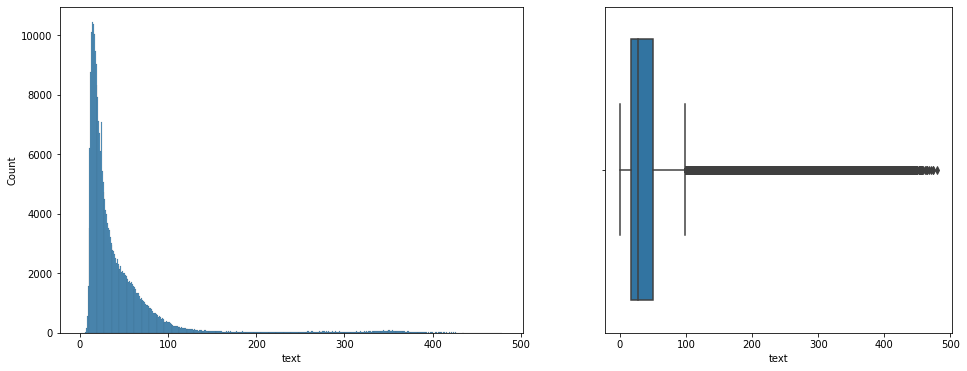

In [ ]:

original_sent_counts = train_data['text'].apply(lambda x: len(x.split(' ')))

fig, axs = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw=dict(width_ratios=[4, 3]))
sns.histplot(original_sent_counts, binwidth=1, ax=axs[0])
sns.boxplot(original_sent_counts, ax=axs[1])

In [ ]:

original_sent_counts = test_cleand['text'].apply(lambda x: len(x.split(' ')))

fig, axs = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw=dict(width_ratios=[4, 3]))
sns.histplot(original_sent_counts, binwidth=1, ax=axs[0])
sns.boxplot(original_sent_counts, ax=axs[1])

/home/link/miniconda3/envs/kobertsum/lib/python3.8/site-packages/seaborn/_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


<AxesSubplot:xlabel='summary'>

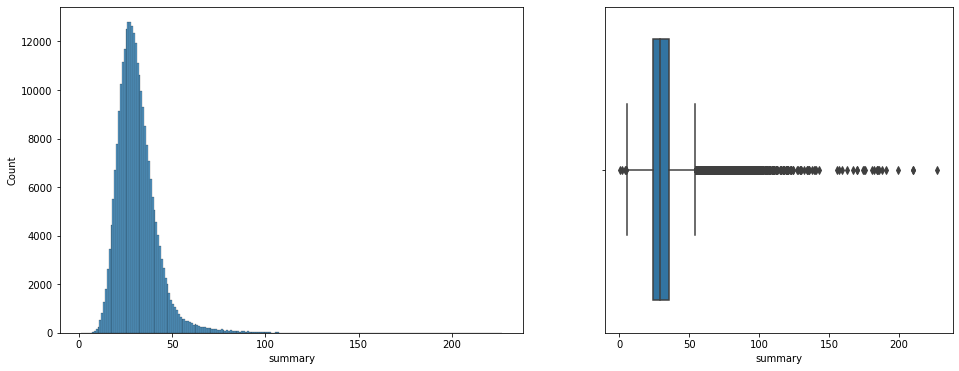

In [ ]:
# sentence
original_sent_counts = train_data['summary'].apply(lambda x: len(x.split(' ')))

fig, axs = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw=dict(width_ratios=[4, 3]))
sns.histplot(original_sent_counts, binwidth=1, ax=axs[0])
sns.boxplot(original_sent_counts, ax=axs[1])

# training

In [ ]:
ROOT_DIR = "/home/link/Project"
PROJECT_DIR = ROOT_DIR + '/KoBertSum_1'
DATA_DIR = PROJECT_DIR + '/datasets/bflysoft_ko'
RAW_DATA_DIR = DATA_DIR + '/raw'
JSON_DATA_DIR = DATA_DIR + '/json'
BERT_DATA_DIR = DATA_DIR + '/bert' 

MODEL_DIR = PROJECT_DIR + '/abs/models'  
LOG_DIR = PROJECT_DIR + '/abs/logs' # logs -> for storing logs information during preprocess and finetuning
RESULT_DIR = PROJECT_DIR + '/abs/result' 

# MERGE_STORY_DIR = PreSumm_DATA_DIR + '/merged_stories_tokenized'  #  tokenized data  
# * **json_data** ->  json files
# * **bert_data** ->  .pt files
# * **logs** ->  for storing logs information during preprocess and finetuning
# * **temp** -> cache model config data
# * **bertsumextabs** ->  save finetuning model weights****

## 데이터 변환

In [ ]:
python make_data.py mode=df_to_bert \
  dataset_name=hunmin_ko src_name=text tgt_name=summary train_split_frac=0.95 \
  n_cpus=28

## Extractive

In [ ]:
python train.py -task ext -mode train -model_name kykim/bert-kor-base -model_path /home/link/Project/KoBertSum_1/ext/models -bert_data_path /home/link/Project/KoBertSum_1/datasets/hunmin_ko/bert -visible_gpus 0,1 -ext_dropout 0.1 -max_pos 512 -batch_size 5000 -accum_count 2 -lr 2e-3 -warmup_steps 5000   -train_steps 15000 -save_checkpoint_steps 300  -report_every 10 -use_interval true -model_path /home/link/Project/KoBertSum_1/abs/models/kykim_bert_0930_12 -log_file /home/link/Project/KoBertSum_1/abs/logs/train_kykim_bert_0930_12.log

In [ ]:
 python main.py -mode valid -model_path kykim_bert_0930_12 -visible_gpus 1 -model_name kykim/bert-kor-base

 python main.py -task ext -mode test -test_from  kykim_bert_0930_12/model_step_2500.pt -visible_gpus 0,1 -model_name kykim/bert-kor-base



In [ ]:
python make_submission_hunmin.py result_kykim_bert_0930_12_step_2500.candidate

## Abstractive

In [ ]:
python main.py -mode train -visible_gpus 0,1 -model_name kykim/bert-kor-base -train_from kykim_bert_0930_12/model_step_2500.pt

In [ ]:
python /home/link/Project/KoBertSum_1/src/train.py \
    -task abs -mode train -bert_data_path '/home/link/Project/KoBertSum_1/datasets/hunmin_ko/bert' \
    -model_path '/home/link/Project/KoBertSum_1/abs/models/kykim_bert_0930_12' \
    -log_file '/home/link/Project/KoBertSum_1/abs/logs/kykim_bert_0930_12.log'\
    -model_name 'kykim/bert-kor-base' \
    -load_from_extractive '/home/link/Project/KoBertSum_1/ext/models/kykim_bert_0930_12/model_step_2500.pt' \
    -dec_dropout 0.2   -sep_optim true -lr_bert 0.002 -lr_dec 0.2 -save_checkpoint_steps 500 -batch_size 140 -train_steps 200000 -report_every 50 -accum_count 5 -use_bert_emb true -use_interval true -warmup_steps_bert 20000 -warmup_steps_dec 10000 -max_pos 512 -visible_gpus 0,1 
    # -train_from "/home/link/Project/KoBertSum_1/abs/models/kykim_bert_0930_12/model_step_2500.pt"

In [ ]:
!python /home/link/Project/KoBertSum_1/src/train.py \
    -task abs -mode train -bert_data_path ‘/home/link/Project/KoBertSum_1/datasets/hunmin_ko/bert’ \
    -model_path ‘/home/link/Project/KoBertSum_1/abs/models/kykim_bert_0930_12’ \
    -log_file ‘/home/link/Project/KoBertSum_1/abs/logs/kykim_bert_0930_12.log’ \
    -model_name ‘kykim/bert-kor-base' \
    -load_from_extractive ‘/home/link/Project/KoBertSum_1/ext/models/kykim_bert_0702_13/model_step_2100.pt’ \
    -dec_dropout 0.2   -sep_optim true -lr_bert 0.002 -lr_dec 0.2 -save_checkpoint_steps 2000 -batch_size 140 -train_steps 100000 -report_every 50 -accum_count 5 -use_bert_emb true -use_interval true -warmup_steps_bert 20000 -warmup_steps_dec 10000 -max_pos 512 -visible_gpus 0,1 

In [ ]:
python main.py -task abs -mode valid -model_path kykim_bert_0930_12 -visible_gpus 0,1 -model_name kykim/bert-kor-base


 python main.py -task abs -mode test -test_from  kykim_bert_0930_12/model_step_5500.pt -visible_gpus 0,1 -model_name kykim/bert-kor-base

python make_submission_ai_online.py result_kykim_bert_0702_13_step_400.candidate -model_name kykim/bert-kor-base
